# Statistical thermodynamics for quantum information science: an understanding guide
### one partition function → qubits, cavities, a 3D box of gas, and the energy cost of a bit, all in SymPy

**In plain words.** A quantum computer is a heat engine problem. Qubits must be colder than the
energy of their own transitions, or heat randomly flips them. Measuring and erasing information
releases heat. The ideal gas, your refrigerator, and a qubit all obey the same statistical
mechanics, built from one object, the **partition function**:

$$Z=\sum_i e^{-\beta E_i},\quad\beta=\frac{1}{k_BT}\qquad\Longrightarrow\qquad
U=-\frac{\partial\ln Z}{\partial\beta},\ F=-k_BT\ln Z,\ S=k_B(\ln Z+\beta U),\ C=\frac{\partial U}{\partial T}.$$

**How to use this guide.** Each section has a plain-language opener, a SymPy derivation you can
check, a number with real units, and a sentence on why QIS engineers care.

| § | system | QIS meaning |
|---|---|---|
| 1 | two-level system | a qubit in contact with a heat bath |
| 2 | harmonic oscillator | a microwave cavity or readout resonator |
| 3 | particle in a 3D box | gas, vacuum, and density of states |
| 4 | bits and heat | Landauer's limit, Szilard's engine |
| 5 | engineering | how cold a quantum computer must be |

Every figure uses the Okabe–Ito colorblind-safe palette, distinguishes curves by line style as
well as color, and has a printed text description.

In [1]:
import numpy as np, matplotlib.pyplot as plt
import sympy as sp
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from dgs import stat_thermo_qis as s
from dgs.stat_thermo_qis import beta, eps, T, k
sp.init_printing()
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)

## 1. The two-level system: a thermal qubit

**In plain words.** A qubit with energy gap $\varepsilon$ sitting in a bath at temperature $T$
is sometimes found excited purely by accident. The ratio $\varepsilon/k_BT$ decides how often.

Feed $Z=1+e^{-\beta\varepsilon}$ into the machine:

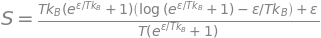

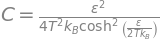

In [2]:
th = s.two_level_symbolic()
for key in ("U", "F", "S", "C"):
    display(sp.Eq(sp.Symbol(key), th[key]))

Three checks, each of which should simplify to zero:
* **thermodynamic entropy = Shannon entropy** of the occupation probabilities, times $k_B$. This is
  where thermodynamics and information theory meet;
* **fluctuation–dissipation:** heat capacity measures energy fluctuations, $\langle\Delta E^2\rangle=k_BT^2C$;
* **von Neumann entropy** of the density matrix $\rho=e^{-\beta H}/Z$ equals the thermodynamic entropy.

In [3]:
print("S_thermo - S_Shannon            =", s.gibbs_equals_shannon_two_level())
print("<dE^2> - k T^2 C                =", s.fluctuation_dissipation_two_level())
rho, bz, d = s.thermal_density_matrix_symbolic()
display(sp.Eq(sp.Symbol("rho_thermal"), rho, evaluate=False))
print("Bloch z of thermal state         =", bz, "    S_vonNeumann - S_thermo =", d)

S_thermo - S_Shannon            = 0
<dE^2> - k T^2 C                = 0


           ⎡   1              ⎤
           ⎢────────     0    ⎥
           ⎢ β⋅ε              ⎥
           ⎢ℯ    + 1          ⎥
           ⎢                  ⎥
ρₜₕₑᵣₘₐₗ = ⎢             β⋅ε  ⎥
           ⎢            ℯ     ⎥
           ⎢   0      ────────⎥
           ⎢           β⋅ε    ⎥
           ⎣          ℯ    + 1⎦

Bloch z of thermal state         = -tanh(beta*epsilon/2)     S_vonNeumann - S_thermo = 0


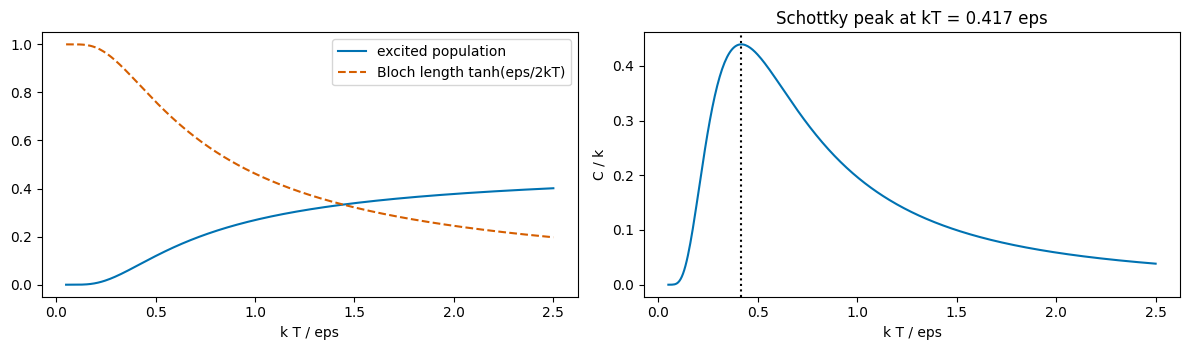

Figure description: left, the excited population rises from 0 toward 1/2 as temperature grows while the Bloch vector length (dashed) falls from 1 toward 0 -- the thermal qubit becomes maximally mixed. Right, the heat capacity has a single peak (Schottky anomaly) near kT = 0.417 eps, marked by a dotted line.


In [4]:
x = np.linspace(0.05, 2.5, 400)                     # kT / eps
p1 = 1/(1+np.exp(1/x)); C = (1/x)**2*np.exp(1/x)/(1+np.exp(1/x))**2
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(x, p1, "-", label="excited population"); ax[0].plot(x, np.tanh(1/(2*x)), "--", label="Bloch length tanh(eps/2kT)")
ax[0].set_xlabel("k T / eps"); ax[0].legend()
ax[1].plot(x, C, "-"); ax[1].axvline(s.schottky_peak(), ls=":", c="k"); ax[1].set_xlabel("k T / eps"); ax[1].set_ylabel("C / k")
ax[1].set_title(f"Schottky peak at kT = {s.schottky_peak():.3f} eps"); plt.tight_layout(); plt.show()
print("Figure description: left, the excited population rises from 0 toward 1/2 as temperature grows while the Bloch "
      "vector length (dashed) falls from 1 toward 0 -- the thermal qubit becomes maximally mixed. Right, the heat capacity "
      "has a single peak (Schottky anomaly) near kT = 0.417 eps, marked by a dotted line.")

In [5]:
for T_K in (0.01, 0.02, 0.1, 4.0, 300.0):
    q = s.thermal_qubit(5e9, T_K)
    print(f"5 GHz qubit at {T_K:7.2f} K:  excited {q['p_excited']:.2e}   Bloch length {q['bloch_length']:.5f}   entropy {q['entropy_bits']:.2e} bits")

5 GHz qubit at    0.01 K:  excited 3.79e-11   Bloch length 1.00000   entropy 1.37e-09 bits
5 GHz qubit at    0.02 K:  excited 6.16e-06   Bloch length 0.99999   entropy 1.15e-04 bits
5 GHz qubit at    0.10 K:  excited 8.32e-02   Bloch length 0.83360   entropy 4.13e-01 bits
5 GHz qubit at    4.00 K:  excited 4.85e-01   Bloch length 0.02999   entropy 9.99e-01 bits
5 GHz qubit at  300.00 K:  excited 5.00e-01   Bloch length 0.00040   entropy 1.00e+00 bits


**Why QIS cares.** At room temperature a 5 GHz qubit is maximally mixed: it holds a full bit
of entropy and zero quantum information. At 20 mK the thermal error is a few parts per million.
"Cooling" a qubit means lowering its entropy.

## 2. The harmonic oscillator: cavities and readout resonators

**In plain words.** A microwave resonator is a ladder of equally spaced levels. Heat fills it with
stray photons, which dephase the qubit it's coupled to.

The partition function is a geometric series (Calc 2 again):

In [6]:
Z, U, nbar = s.oscillator_symbolic()
display(sp.Eq(sp.Symbol("Z"), Z), sp.Eq(sp.Symbol("U"), U), sp.Eq(sp.Symbol("n_bar"), nbar))

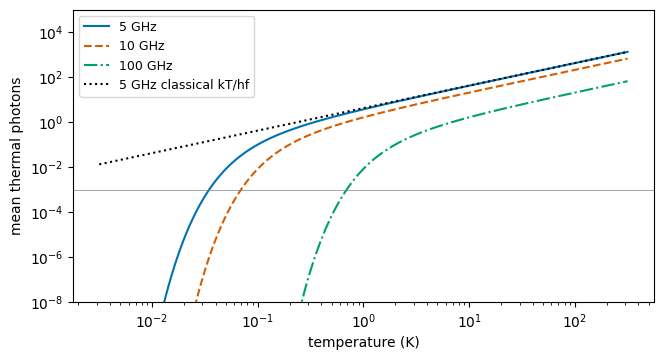

5 GHz cavity: 6.2e-06 photons at 20 mK, 16.2 at 4 K, 1250 at 300 K
Figure description: mean thermal photon number versus temperature for 5, 10, and 100 GHz modes; each follows the classical straight line kT/hf at high temperature and drops exponentially once kT < hf. Higher frequencies freeze out at higher temperatures.


In [7]:
Ts = np.logspace(-2.5, 2.5, 300)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for f_, ls in ((5e9, "-"), (10e9, "--"), (100e9, "-.")):
    ax.loglog(Ts, s.bose_occupation(f_, Ts), ls=ls, label=f"{f_/1e9:.0f} GHz")
ax.loglog(Ts, s.K_B*Ts/(s.H*5e9), ":", c="k", label="5 GHz classical kT/hf")
ax.axhline(1e-3, c="0.5", lw=0.5); ax.set_ylim(1e-8, 1e5)
ax.set_xlabel("temperature (K)"); ax.set_ylabel("mean thermal photons"); ax.legend(fontsize=9); plt.show()
print(f"5 GHz cavity: {s.bose_occupation(5e9, 0.02):.1e} photons at 20 mK, {s.bose_occupation(5e9, 4):.1f} at 4 K, {s.bose_occupation(5e9, 300):.0f} at 300 K")
print("Figure description: mean thermal photon number versus temperature for 5, 10, and 100 GHz modes; each follows the "
      "classical straight line kT/hf at high temperature and drops exponentially once kT < hf. Higher frequencies freeze "
      "out at higher temperatures.")

**Why QIS cares.** At 4 K (liquid helium) a 5 GHz mode still holds about 16 thermal photons.
Only a dilution refrigerator, around 10–20 mK, empties it. Optical photons (hundreds of THz) are
frozen out even at room temperature, which is one reason photonic qubits can run warm.

## 3. A particle in a 3D box: degeneracy, geometry, and the ideal gas

**In plain words.** In a cubic box, the energy is $\propto n_x^2+n_y^2+n_z^2$. Counting states
means counting integer points in a sphere, which is 3D geometry. The count turns into the ideal
gas law and the entropy of real gases.

**Degeneracy, by loop and vectorized:**

In [8]:
Emax = 40000
t0 = time.perf_counter(); a = s.count_states_loop(Emax); t1 = time.perf_counter(); b = s.count_states_vectorized(Emax); t2 = time.perf_counter()
print(f"states with n^2 <= {Emax}: loop {a:,} ({1e3*(t1-t0):.0f} ms), vectorized {b:,} ({1e3*(t2-t1):.0f} ms) -> {(t1-t0)/(t2-t1):.0f}x faster")
print("first degeneracies (energy: count):", dict(list(s.degeneracies(30).items())[:10]))
N_oct, g, E = s.octant_count_symbolic()
display(sp.Eq(sp.Symbol("N(E) (octant of a sphere)"), N_oct), sp.Eq(sp.Symbol("g(E) = dN/dE"), g))
lead = float(N_oct.subs(E, Emax)); surf = float(3*sp.pi/8*Emax)
print(f"octant volume {lead:,.0f}; minus surface term (3 pi/8) E = {lead - surf:,.0f}; exact {b:,}")

states with n^2 <= 40000: loop 4,141,525 (488 ms), vectorized 4,141,525 (17 ms) -> 28x faster
first degeneracies (energy: count): {3: 1, 6: 3, 9: 3, 11: 3, 12: 1, 14: 6, 17: 3, 18: 3, 19: 3, 21: 6}


octant volume 4,188,790; minus surface term (3 pi/8) E = 4,141,666; exact 4,141,525


The states fill one **octant** (all $n_i\ge1$) of a sphere of radius $\sqrt E$. The volume
gives the leading count, and the faces where some $n_i=0$ (which are excluded) give a surface
correction $-(3\pi/8)E$. With it, the formula matches the exact count to about $10^{-4}$. The
$\sqrt E$ density of states is why 3D gases, electrons in metals, and blackbody photons all have
$E^{1/2}$ or $E^2$ factors.

**From the box to the gas:** in the classical limit, each momentum integral is a Gaussian:

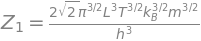

Z_1 - (L/lambda)^3 = 0
Sackur-Tetrode check S - N k [ln(V/(N lambda^3)) + 5/2] = 0
helium : Sackur-Tetrode  126.15 J/(mol K)   standard tables ~126.2
neon   : Sackur-Tetrode  146.33 J/(mol K)   standard tables ~146.3
argon  : Sackur-Tetrode  154.85 J/(mol K)   standard tables ~154.8


In [9]:
Z1, resid = s.translational_Z_symbolic()
display(sp.Eq(sp.Symbol("Z_1"), Z1)); print("Z_1 - (L/lambda)^3 =", resid)
print("Sackur-Tetrode check S - N k [ln(V/(N lambda^3)) + 5/2] =", s.sackur_tetrode_symbolic())
for name, m_amu, tab in (("helium", 4.0026, 126.2), ("neon", 20.18, 146.3), ("argon", 39.948, 154.8)):
    print(f"{name:7s}: Sackur-Tetrode {s.sackur_tetrode_molar(m_amu):7.2f} J/(mol K)   standard tables ~{tab}")

Quantum mechanics (Planck's $h$ inside $\lambda$) and counting ($N!$, which treats atoms as
indistinguishable) predict the absolute entropy of noble gases to 0.1%. And the 3D speed
distribution, with its $4\pi v^2$ shell factor (geometry again):

In [10]:
norm, mean, rms, vp = s.maxwell_speed_symbolic()
print("normalization:", norm)
display(sp.Eq(sp.Symbol("<v>"), mean), sp.Eq(sp.Symbol("v_rms"), rms), sp.Eq(sp.Symbol("v_p"), vp))
m_rb = 86.909*s.AMU
for T_K in (300, 1e-3, 1e-6):
    print(f"Rb-87 at {T_K:g} K: v_rms = {np.sqrt(3*s.K_B*T_K/m_rb):.3g} m/s")

normalization: 1


Rb-87 at 300 K: v_rms = 293 m/s
Rb-87 at 0.001 K: v_rms = 0.536 m/s
Rb-87 at 1e-06 K: v_rms = 0.0169 m/s


Laser cooling takes rubidium from hundreds of m/s to centimeters per second. That's how the
atom interferometers and clocks in this repo get atoms slow enough to measure.

## 4. Information is physical: bits, heat, and Landauer's limit

**In plain words.** A bit that could be 0 or 1 has entropy $k_B\ln2$. Resetting it to 0 removes
that entropy from the bit, so the second law says at least $k_BT\ln2$ of heat must go somewhere
else. Run it backwards: knowing which half of a box a molecule is in lets you extract
$k_BT\ln2$ of work (Szilard's engine).

In [11]:
display(sp.Eq(sp.Symbol("Delta S (erase 1 bit)"), s.bit_entropy_symbolic()))
display(sp.Eq(sp.Symbol("W_Szilard"), s.szilard_work_symbolic()))
for T_K in (300, 4, 0.02):
    print(f"Landauer limit at {T_K:6.2f} K: {s.landauer_limit(T_K):.3e} J = {s.landauer_limit(T_K)/1.602176634e-19*1e3:.4f} meV per bit")

Landauer limit at 300.00 K: 2.871e-21 J = 17.9192 meV per bit
Landauer limit at   4.00 K: 3.828e-23 J = 0.2389 meV per bit
Landauer limit at   0.02 K: 1.914e-25 J = 0.0012 meV per bit


**Why QIS cares.**
* Measuring a qubit and then resetting it for reuse is erasure, and the reset heat has to flow out
  through the refrigerator.
* Reversible (unitary) quantum gates erase nothing, so in principle they cost no Landauer heat.
  That's the deep link between reversible computing and quantum computing.
* Practical electronics dissipate far more than $k_BT\ln2$ per operation today. The limit is a
  floor, not a current engineering target.

## 5. Engineering: how cold must a quantum computer be?

Set a target thermal error, for example an excited population of $10^{-3}$, and solve for $T$:

In [12]:
for f_ in (1e9, 5e9, 10e9, 100e9, 200e12):
    Tq = s.required_temperature(f_, 1e-3)
    label = "optical photon" if f_ > 1e12 else f"{f_/1e9:g} GHz"
    print(f"{label:15s}: T < {Tq:10.4g} K for <0.1% thermal excitation")

1 GHz          : T <   0.006949 K for <0.1% thermal excitation
5 GHz          : T <    0.03474 K for <0.1% thermal excitation
10 GHz         : T <    0.06949 K for <0.1% thermal excitation
100 GHz        : T <     0.6949 K for <0.1% thermal excitation
optical photon : T <       1390 K for <0.1% thermal excitation


Superconducting qubits (a few GHz) need tens of millikelvin: a dilution refrigerator.
Spin qubits and trapped ions trade frequency, temperature and laser cooling differently. Optical
photonic qubits run at room temperature but face other limits, such as loss and detector
cooling. The table above is a big part of why quantum hardware platforms look so different.

## 6. Where this connects

* **This repo:**
  - `cell_hilbert_bridge` and `dephasing_phase_retrieval` (density matrices, entropy);
  - `atomic_clock` (cold atoms, Ramsey);
  - `nv_magnetometer` (spin populations; an NV's optical pumping makes it far colder than its
    surroundings);
  - `hawking_qis` (black-hole entropy: the same $S=k_B\ln(\text{states})$ at its most extreme).
* **Griffiths → ML:** the Boltzmann distribution $p_i\propto e^{-\beta E_i}$ is the **softmax**
  function. $\beta$ is the inverse "temperature" used in sampling from language models and in
  energy-based models.
* **IEEE venues for engineering-side QIS:** *IEEE Transactions on Quantum Engineering* and the
  IEEE Quantum Week conference (QCE) publish this kind of hardware-and-systems work. Check the
  current calls before submitting.

## Summary

| idea | SymPy result |
|---|---|
| two-level $U,S,C$ | from $Z=1+e^{-\beta\varepsilon}$; Schottky peak at $kT\approx0.417\varepsilon$ |
| entropy unification | thermodynamic = Shannon × $k_B$ = von Neumann (all residuals 0) |
| fluctuations | $\langle\Delta E^2\rangle=k_BT^2C$ |
| oscillator | $Z=1/(2\sinh(\beta\hbar\omega/2))$, $\bar n=1/(e^{\beta\hbar\omega}-1)$ |
| 3D box | octant volume − surface term matches exact count; $g(E)\propto\sqrt E$ |
| ideal gas | $Z_1=V/\lambda^3$; Sackur–Tetrode matches He/Ne/Ar to ~0.1% |
| information | erase 1 bit: $\Delta S=k_B\ln2$; Szilard $W=k_BT\ln2$ |
| engineering | 5 GHz qubit: $T\lesssim35$ mK for $10^{-3}$ thermal error |

*Constants are CODATA/SI; tabulated entropies are standard reference values. Education.*